# Step 4: Stock Transfer Optimization

**TradeFlow AI — Tradeling Hackathon**

Using the demonstration scenario from Step 3.1, this step:

1. Identifies SKU-level shortage/surplus pairs across warehouses
2. Calculates transferable stock respecting source safety-stock constraints
3. Accounts for transfer lead times and route costs
4. Optimizes transfers using **scipy.optimize.milp** (HiGHS solver, cost-aware integer optimization)
5. Simulates post-transfer daily inventory
6. Produces human-readable recommendations (all `Pending` approval)

### Key Constraints

- Transfers dispatched at the **start** of the planning horizon
- Transferred inventory leaves source **immediately**
- Transferred inventory arrives at destination only after **route lead time**
- A transfer **cannot prevent** a shortage that occurs before its arrival
- Source safety stock must be preserved at all times
- No source inventory allocated to multiple destinations
- All transfer quantities are **nonnegative integers**

---
## 1. Load Existing Data

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from datetime import timedelta

DATA_DIR = Path(r"C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets")

# --- Scenario inventory ---
scenario_inventory = pd.read_csv(DATA_DIR / "scenario_inventory.csv")

# --- Scenario inventory risks (from Step 3.1) ---
scenario_risks = pd.read_csv(DATA_DIR / "scenario_inventory_risks.csv")

# --- Scenario daily projection (from Step 3.1) ---
scenario_daily = pd.read_csv(DATA_DIR / "scenario_daily_inventory_projection.csv")
scenario_daily["Date"] = pd.to_datetime(scenario_daily["Date"])

# --- Scenario inbound orders ---
scenario_inbound = pd.read_csv(DATA_DIR / "scenario_inbound_orders.csv")
scenario_inbound["Expected_Arrival"] = pd.to_datetime(scenario_inbound["Expected_Arrival"])

# --- Forecasts (improved XGBoost) ---
daily_forecast = pd.read_csv(DATA_DIR / "improved_daily_forecasts.csv")
daily_forecast["Date"] = pd.to_datetime(daily_forecast["Date"])
forecast_30d = pd.read_csv(DATA_DIR / "improved_forecast_30d.csv")

# --- Transfer routes ---
transfer_routes = pd.read_csv(DATA_DIR / "transfer_routes.csv")

# --- Products ---
products = pd.read_csv(DATA_DIR / "products.csv")

# --- Warehouses ---
warehouses = pd.read_csv(DATA_DIR / "warehouses.csv")

print("Data loaded:")
print(f"  scenario_inventory      : {scenario_inventory.shape}")
print(f"  scenario_risks          : {scenario_risks.shape}")
print(f"  scenario_daily          : {scenario_daily.shape}")
print(f"  scenario_inbound        : {scenario_inbound.shape}")
print(f"  daily_forecast          : {daily_forecast.shape}")
print(f"  forecast_30d            : {forecast_30d.shape}")
print(f"  transfer_routes         : {transfer_routes.shape}")
print(f"  products                : {products.shape}")
print(f"  warehouses              : {warehouses.shape}")

Data loaded:
  scenario_inventory      : (60, 5)
  scenario_risks          : (60, 37)
  scenario_daily          : (1800, 15)
  scenario_inbound        : (15, 6)
  daily_forecast          : (1800, 4)
  forecast_30d            : (60, 6)
  transfer_routes         : (6, 4)
  products                : (20, 7)
  warehouses              : (3, 3)


### 1.1 Inspect transfer routes

In [2]:
print("Transfer Routes:")
print(transfer_routes.to_string(index=False))
print(f"\nWarehouses: {warehouses['Warehouse'].tolist()}")
print(f"\nRoute costs range: {transfer_routes['Cost_Per_Unit_AED'].min()}–{transfer_routes['Cost_Per_Unit_AED'].max()} AED/unit")
print(f"Lead times range: {transfer_routes['Lead_Time_Days'].min()}–{transfer_routes['Lead_Time_Days'].max()} days")

Transfer Routes:
   Origin Destination  Cost_Per_Unit_AED  Lead_Time_Days
    Dubai   Abu Dhabi                2.0               1
Abu Dhabi       Dubai                2.0               1
    Dubai     Sharjah                1.0               1
  Sharjah       Dubai                1.0               1
Abu Dhabi     Sharjah                2.5               2
  Sharjah   Abu Dhabi                2.5               2

Warehouses: ['Dubai', 'Abu Dhabi', 'Sharjah']

Route costs range: 1.0–2.5 AED/unit
Lead times range: 1–2 days


### 1.2 Prepare lookup dictionaries

In [3]:
# Build lookup dictionaries for fast access
WH_LIST = sorted(scenario_inventory["Warehouse"].unique())
SKU_LIST = sorted(scenario_inventory["SKU"].unique())
FUTURE_DATES = sorted(daily_forecast["Date"].unique())
N_DAYS = len(FUTURE_DATES)
HORIZON_START = FUTURE_DATES[0]
HORIZON_END = FUTURE_DATES[-1]

# (SKU, Warehouse) -> available stock
available_map = scenario_inventory.set_index(["SKU", "Warehouse"])["Available_Stock"].to_dict()
# (SKU, Warehouse) -> safety stock
safety_map = scenario_inventory.set_index(["SKU", "Warehouse"])["Safety_Stock"].to_dict()
# (SKU, Warehouse) -> reserved stock
reserved_map = scenario_inventory.set_index(["SKU", "Warehouse"])["Reserved_Stock"].to_dict()

# (SKU, Warehouse) -> forecast 30d
forecast_30d_map = forecast_30d.set_index(["SKU", "Warehouse"])["Forecast_30d"].to_dict()

# (SKU, Warehouse, Date) -> daily demand forecast
demand_map = {}
for _, row in daily_forecast.iterrows():
    demand_map[(row["SKU"], row["Warehouse"], row["Date"])] = row["Predicted_Demand"]

# (SKU, Warehouse, Date) -> inbound quantity
inbound_map = {}
for _, row in scenario_inbound.iterrows():
    key = (row["SKU"], row["Warehouse"], row["Expected_Arrival"])
    inbound_map[key] = inbound_map.get(key, 0) + row["Quantity"]

# (Origin, Destination) -> (cost, lead_time)
route_map = {}
for _, row in transfer_routes.iterrows():
    route_map[(row["Origin"], row["Destination"])] = {
        "cost": row["Cost_Per_Unit_AED"],
        "lead_time": int(row["Lead_Time_Days"]),
    }

# SKU -> profit margin
margin_map = products.set_index("SKU")["Profit_Margin_AED"].to_dict()
# SKU -> holding cost per unit per day
holding_cost_map = products.set_index("SKU")["Holding_Cost_Per_Unit_Day_AED"].to_dict()
# SKU -> product name
product_name_map = products.set_index("SKU")["Product"].to_dict()

print(f"Lookups prepared:")
print(f"  SKUs: {len(SKU_LIST)}, Warehouses: {len(WH_LIST)}")
print(f"  Forecast dates: {N_DAYS} ({HORIZON_START.date()} → {HORIZON_END.date()})")
print(f"  Routes: {len(route_map)}")
print(f"  Daily demand entries: {len(demand_map)}")
print(f"  Inbound entries: {len(inbound_map)}")

Lookups prepared:
  SKUs: 20, Warehouses: 3
  Forecast dates: 30 (2026-09-29 → 2026-10-28)
  Routes: 6
  Daily demand entries: 1800
  Inbound entries: 15


---

## 2. Baseline Simulation (Before Transfers)

Re-run the daily inventory simulation to establish the **before-transfers** baseline.
This gives us per-day unmet demand, which we need to evaluate transfer effectiveness.

In [4]:
def simulate_inventory(transfers=None, verbose=False):
    """
    Simulate daily inventory for all SKU-warehouse combos.

    Parameters
    ----------
    transfers : list of dict, each with keys:
        SKU, Source, Destination, Quantity, Lead_Time_Days
        If None, simulates without transfers (baseline).

    Returns
    -------
    daily_df : DataFrame with daily projection
    summary : dict with aggregate results
    """
    if transfers is None:
        transfers = []

    # Build transfer schedule
    # Outgoing: (sku, source) -> total qty dispatched at horizon start
    # Incoming: (sku, destination, arrival_date) -> qty arriving
    transfer_out = {}
    transfer_in = {}

    for t in transfers:
        sku = t["SKU"]
        src = t["Source"]
        dst = t["Destination"]
        qty = t["Quantity"]
        lt = t["Lead_Time_Days"]

        # Dispatch at horizon start (leaves source immediately)
        transfer_out[(sku, src)] = transfer_out.get((sku, src), 0) + qty

        # Arrival at destination after lead time
        arrival_date = HORIZON_START + timedelta(days=lt)
        transfer_in[(sku, dst, arrival_date)] = transfer_in.get((sku, dst, arrival_date), 0) + qty

    daily_rows = []
    combo_results = {}

    for sku in SKU_LIST:
        for wh in WH_LIST:
            # Starting stock: available minus any transfers out
            stock = float(available_map[(sku, wh)])
            safety = float(safety_map[(sku, wh)])
            outgoing = transfer_out.get((sku, wh), 0)
            stock -= outgoing  # transferred out at start
            stock = max(0, stock)

            starting_stock = stock
            cumulative_demand = 0.0
            cumulative_inbound = 0.0
            cumulative_fulfilled = 0.0
            cumulative_unmet = 0.0
            cumulative_transfer_in = 0.0
            first_stockout_date = None
            days_below_safety = 0

            for day_idx, dt in enumerate(FUTURE_DATES):
                # Inbound shipment arriving today
                incoming_ship = inbound_map.get((sku, wh, dt), 0)
                stock += incoming_ship
                cumulative_inbound += incoming_ship

                # Transfer arriving today
                incoming_transfer = transfer_in.get((sku, wh, dt), 0)
                stock += incoming_transfer
                cumulative_transfer_in += incoming_transfer

                # Daily demand
                demand = demand_map.get((sku, wh, dt), 0.0)
                cumulative_demand += demand

                # Fulfill demand
                fulfilled = min(stock, demand)
                unmet = max(0, demand - stock)
                stock = max(0, stock - fulfilled)
                cumulative_fulfilled += fulfilled
                cumulative_unmet += unmet

                # Track stockout
                if stock <= 0 and first_stockout_date is None:
                    first_stockout_date = dt

                # Safety stock violation
                if stock < safety:
                    days_below_safety += 1

                daily_rows.append({
                    "Date": dt,
                    "SKU": sku,
                    "Warehouse": wh,
                    "Starting_Stock": starting_stock if day_idx == 0 else None,
                    "Incoming_Qty": incoming_ship,
                    "Transfer_In_Qty": incoming_transfer,
                    "Transfer_Out_Qty": outgoing if day_idx == 0 else 0,
                    "Daily_Demand": demand,
                    "Fulfilled_Demand": fulfilled,
                    "Unmet_Demand": unmet,
                    "Ending_Stock": stock,
                    "Cumulative_Inbound": cumulative_inbound,
                    "Cumulative_Demand": cumulative_demand,
                    "Cumulative_Fulfilled": cumulative_fulfilled,
                    "Cumulative_Unmet": cumulative_unmet,
                    "Safety_Stock": safety,
                    "Below_Safety_Stock": stock < safety,
                })
                starting_stock = stock

            combo_results[(sku, wh)] = {
                "Starting_Stock": available_map[(sku, wh)] - outgoing,
                "Total_Incoming": cumulative_inbound,
                "Total_Transfer_In": cumulative_transfer_in,
                "Total_Transfer_Out": outgoing,
                "Total_Demand": cumulative_demand,
                "Total_Fulfilled": cumulative_fulfilled,
                "Total_Unmet_Demand": cumulative_unmet,
                "Ending_Stock": stock,
                "First_Stockout_Date": first_stockout_date,
                "Days_Below_Safety": days_below_safety,
            }

    daily_df = pd.DataFrame(daily_rows)
    daily_df = daily_df.sort_values(["SKU", "Warehouse", "Date"]).reset_index(drop=True)

    # Fill Starting_Stock forward
    for (sku, wh), grp in daily_df.groupby(["SKU", "Warehouse"]):
        prev = None
        for idx in grp.index:
            if pd.isna(daily_df.at[idx, "Starting_Stock"]):
                daily_df.at[idx, "Starting_Stock"] = prev
            prev = daily_df.at[idx, "Ending_Stock"]

    total_unmet = sum(r["Total_Unmet_Demand"] for r in combo_results.values())
    total_demand = sum(r["Total_Demand"] for r in combo_results.values())
    total_fulfilled = sum(r["Total_Fulfilled"] for r in combo_results.values())

    summary = {
        "total_unmet": total_unmet,
        "total_demand": total_demand,
        "total_fulfilled": total_fulfilled,
        "combo_results": combo_results,
        "daily_df": daily_df,
    }

    if verbose:
        print(f"Total demand: {total_demand:.1f}, Fulfilled: {total_fulfilled:.1f}, Unmet: {total_unmet:.1f}")

    return daily_df, summary

# Run baseline simulation
baseline_daily, baseline_summary = simulate_inventory(verbose=True)
print(f"\nBaseline daily projection: {baseline_daily.shape}")
print(f"Combos with unmet demand: {sum(1 for r in baseline_summary['combo_results'].values() if r['Total_Unmet_Demand'] > 0)}")

Total demand: 6385.1, Fulfilled: 5265.4, Unmet: 1119.7

Baseline daily projection: (1800, 17)
Combos with unmet demand: 26


---

## 3. Identify Transfer Candidates

For each SKU, match warehouses with projected shortages to warehouses with transferable surplus.
Only consider pairs where a valid transfer route exists.

In [5]:
# Identify shortage and surplus warehouses per SKU
shortage_combos = []
surplus_combos = []

for sku in SKU_LIST:
    for wh in WH_LIST:
        result = baseline_summary["combo_results"][(sku, wh)]
        unmet = result["Total_Unmet_Demand"]
        ending = result["Ending_Stock"]
        safety = safety_map[(sku, wh)]
        available = available_map[(sku, wh)]
        fc30 = forecast_30d_map[(sku, wh)]

        if unmet > 0:
            shortage_combos.append({
                "SKU": sku,
                "Warehouse": wh,
                "Unmet_Demand": unmet,
                "Safety_Stock": safety,
                "Available_Stock": available,
                "Ending_Stock": ending,
            })

        # Surplus: ending stock well above safety AND above forecast
        if ending > 2 * safety and ending > fc30 * 0.5:
            surplus_combos.append({
                "SKU": sku,
                "Warehouse": wh,
                "Ending_Stock": ending,
                "Safety_Stock": safety,
                "Available_Stock": available,
            })

shortage_df = pd.DataFrame(shortage_combos)
surplus_df = pd.DataFrame(surplus_combos)

print(f"Shortage warehouses: {len(shortage_df)}")
print(f"Surplus warehouses:  {len(surplus_df)}")
print(f"\nShortage combos by warehouse:")
print(shortage_df.groupby("Warehouse")["Unmet_Demand"].agg(["count", "sum"]).to_string())
print(f"\nSurplus combos by warehouse:")
print(surplus_df.groupby("Warehouse")["Ending_Stock"].agg(["count", "sum"]).to_string())

Shortage warehouses: 26
Surplus warehouses:  24

Shortage combos by warehouse:
           count         sum
Warehouse                   
Abu Dhabi      8  353.204579
Dubai          9  437.648556
Sharjah        9  328.841459

Surplus combos by warehouse:
           count          sum
Warehouse                    
Abu Dhabi      9  2479.227530
Dubai          8  2253.629278
Sharjah        7  1517.074073


### 3.1 Match shortages to surplus sources via routes

In [6]:
# Build transfer candidate pairs
candidates = []

for sku in SKU_LIST:
    sku_shortages = shortage_df[shortage_df["SKU"] == sku]
    sku_surpluses = surplus_df[surplus_df["SKU"] == sku]

    if sku_shortages.empty or sku_surpluses.empty:
        continue

    for _, s_row in sku_shortages.iterrows():
        dst_wh = s_row["Warehouse"]
        unmet = s_row["Unmet_Demand"]

        for _, x_row in sku_surpluses.iterrows():
            src_wh = x_row["Warehouse"]
            if src_wh == dst_wh:
                continue

            # Check route exists
            route_key = (src_wh, dst_wh)
            if route_key not in route_map:
                continue

            route_info = route_map[route_key]
            cost_per_unit = route_info["cost"]
            lead_time = route_info["lead_time"]
            margin = margin_map[sku]

            # Net benefit per unit = margin - transfer cost
            net_benefit_per_unit = margin - cost_per_unit

            candidates.append({
                "SKU": sku,
                "Source_Warehouse": src_wh,
                "Destination_Warehouse": dst_wh,
                "Lead_Time_Days": lead_time,
                "Cost_Per_Unit_AED": cost_per_unit,
                "Profit_Margin_AED": margin,
                "Net_Benefit_Per_Unit_AED": net_benefit_per_unit,
                "Destination_Unmet_Demand": unmet,
                "Source_Ending_Stock": x_row["Ending_Stock"],
                "Source_Safety_Stock": x_row["Safety_Stock"],
            })

candidates_df = pd.DataFrame(candidates)
print(f"Transfer candidate pairs: {len(candidates_df)}")
print(f"SKUs with candidates: {candidates_df['SKU'].nunique()}")
print(f"\nBeneficial candidates (net_benefit > 0): {(candidates_df['Net_Benefit_Per_Unit_AED'] > 0).sum()}")
print(f"Candidates with zero/negative benefit: {(candidates_df['Net_Benefit_Per_Unit_AED'] <= 0).sum()}")
print(f"\nCandidate summary:")
print(candidates_df[["SKU", "Source_Warehouse", "Destination_Warehouse", "Lead_Time_Days",
                     "Cost_Per_Unit_AED", "Profit_Margin_AED", "Net_Benefit_Per_Unit_AED",
                     "Destination_Unmet_Demand"]].to_string(index=False))

Transfer candidate pairs: 30
SKUs with candidates: 18

Beneficial candidates (net_benefit > 0): 30
Candidates with zero/negative benefit: 0

Candidate summary:
    SKU Source_Warehouse Destination_Warehouse  Lead_Time_Days  Cost_Per_Unit_AED  Profit_Margin_AED  Net_Benefit_Per_Unit_AED  Destination_Unmet_Demand
SKU-002        Abu Dhabi               Sharjah               2                2.5              69.24                     66.74                 45.051574
SKU-003        Abu Dhabi                 Dubai               1                2.0              17.74                     15.74                116.741751
SKU-005            Dubai             Abu Dhabi               1                2.0              13.89                     11.89                 70.957447
SKU-005            Dubai               Sharjah               1                1.0              13.89                     12.89                  7.883168
SKU-006            Dubai               Sharjah               1             

---

## 4. Calculate Transferable Stock

For each source warehouse, calculate the **maximum stock transferable** without
creating new shortages or violating safety-stock requirements.

### Formula

Transferable = Available_Stock − (Forecast_30d + Safety_Stock)

Only stock available **at the start** is transferable (future inbound shipments
do not count as immediately transferable).

If the result is negative, no stock can be transferred.

In [7]:
def calculate_transferable_stock(sku, wh, already_transferring_out=0):
    """
    Calculate max stock that can be transferred out of (sku, wh)
    without causing a shortage or violating safety stock.

    Transferable = Available_Stock - Forecast_30d - Safety_Stock - already_transferring_out
    (only stock available at start counts; future inbound does NOT count)
    """
    available = available_map.get((sku, wh), 0)
    fc_30d = forecast_30d_map.get((sku, wh), 0)
    safety = safety_map.get((sku, wh), 0)

    # Stock needed to cover forecast demand + safety buffer
    needed = fc_30d + safety + already_transferring_out
    transferable = available - needed
    return max(0, int(np.floor(transferable)))

# Calculate transferable stock for all surplus combos
transferable_rows = []
for _, row in surplus_df.iterrows():
    sku = row["SKU"]
    wh = row["Warehouse"]
    t = calculate_transferable_stock(sku, wh)
    transferable_rows.append({
        "SKU": sku,
        "Warehouse": wh,
        "Available_Stock": row["Available_Stock"],
        "Forecast_30d": forecast_30d_map[(sku, wh)],
        "Safety_Stock": row["Safety_Stock"],
        "Transferable_Stock": t,
    })

transferable_df = pd.DataFrame(transferable_rows)
transferable_df = transferable_df[transferable_df["Transferable_Stock"] > 0].reset_index(drop=True)

print(f"Sources with transferable stock: {len(transferable_df)}")
print(f"Total transferable units: {transferable_df['Transferable_Stock'].sum()}")
print(f"\nTransferable stock by warehouse:")
print(transferable_df.groupby("Warehouse")["Transferable_Stock"].agg(["count", "sum"]).to_string())
print(f"\nDetails:")
print(transferable_df.to_string(index=False))

Sources with transferable stock: 22
Total transferable units: 5348

Transferable stock by warehouse:
           count   sum
Warehouse             
Abu Dhabi      8  2112
Dubai          8  1856
Sharjah        6  1380

Details:
    SKU Warehouse  Available_Stock  Forecast_30d  Safety_Stock  Transferable_Stock
SKU-001     Dubai              166        121.52            24                  20
SKU-002 Abu Dhabi              182         74.63            15                  92
SKU-003 Abu Dhabi              550        159.73            32                 358
SKU-004 Abu Dhabi              131         78.08            16                  36
SKU-005     Dubai              363        143.12            29                 190
SKU-006     Dubai              433        147.25            29                 256
SKU-007     Dubai              378         79.57            16                 282
SKU-007   Sharjah              284         61.78            12                 210
SKU-008 Abu Dhabi          

---

## 5. Optimize Transfers

### Approach: scipy.optimize.milp (Mixed-Integer Linear Program)

**Decision variables:** For each candidate (SKU, Source, Destination) pair,
a nonnegative integer variable representing the transfer quantity.

**Objective:** Maximize net economic benefit (margin preserved minus transfer cost).

**Constraints:**
1. Source capacity: total out from each (SKU, source) <= transferable stock
2. Destination need: transfer to each (SKU, dest) <= unmet demand
3. Lead-time effectiveness: only count units that arrive before stockout
4. Nonnegative integers

In [8]:
import pulp

# Build a lookup of per-day unmet demand for each shortage combo
shortage_daily = {}
for _, row in shortage_df.iterrows():
    sku = row["SKU"]
    wh = row["Warehouse"]
    daily_data = baseline_daily[(baseline_daily["SKU"] == sku) &
                                (baseline_daily["Warehouse"] == wh)].sort_values("Date")
    # Cumulative unmet demand by day
    cum_unmet_by_day = {}
    running = 0.0
    for _, d in daily_data.iterrows():
        running += d["Unmet_Demand"]
        cum_unmet_by_day[d["Date"]] = running
    shortage_daily[(sku, wh)] = {
        "daily": daily_data,
        "cum_unmet_by_day": cum_unmet_by_day,
        "total_unmet": row["Unmet_Demand"],
    }

# Filter candidates: only keep those with transferable stock and positive net benefit
valid_candidates = []
for _, c in candidates_df.iterrows():
    sku = c["SKU"]
    src = c["Source_Warehouse"]
    dst = c["Destination_Warehouse"]

    # Check source has transferable stock
    t_row = transferable_df[(transferable_df["SKU"] == sku) &
                            (transferable_df["Warehouse"] == src)]
    if t_row.empty:
        continue
    transferable = t_row["Transferable_Stock"].values[0]
    if transferable <= 0:
        continue

    # Check net benefit is positive
    if c["Net_Benefit_Per_Unit_AED"] <= 0:
        continue

    # Calculate how much unmet demand can actually be reduced by this transfer
    arrival_day = HORIZON_START + timedelta(days=int(c["Lead_Time_Days"]))

    sd = shortage_daily[(sku, dst)]
    cum_unmet_before_arrival = 0.0
    cum_unmet_total = sd["total_unmet"]

    for dt, cum in sd["cum_unmet_by_day"].items():
        if dt < arrival_day:
            cum_unmet_before_arrival = cum

    # Unmet demand that can potentially be reduced = total - before_arrival
    reducible_unmet = max(0, cum_unmet_total - cum_unmet_before_arrival)

    if reducible_unmet <= 0:
        continue  # Transfer arrives too late, no benefit

    valid_candidates.append({
        **c.to_dict(),
        "Transferable_Stock": transferable,
        "Arrival_Date": arrival_day,
        "Reducible_Unmet_Demand": reducible_unmet,
        "Cum_Unmet_Before_Arrival": cum_unmet_before_arrival,
    })

valid_df = pd.DataFrame(valid_candidates)
print(f"Valid transfer candidates (after filtering): {len(valid_df)}")
print(f"  With transferable stock > 0")
print(f"  With positive net benefit")
print(f"  With reducible unmet demand (arrives before stockout)")
print(f"\nValid candidates:")
print(valid_df[["SKU", "Source_Warehouse", "Destination_Warehouse", "Lead_Time_Days",
                "Cost_Per_Unit_AED", "Net_Benefit_Per_Unit_AED", "Transferable_Stock",
                "Reducible_Unmet_Demand"]].to_string(index=False))

Valid transfer candidates (after filtering): 28
  With transferable stock > 0
  With positive net benefit
  With reducible unmet demand (arrives before stockout)

Valid candidates:
    SKU Source_Warehouse Destination_Warehouse  Lead_Time_Days  Cost_Per_Unit_AED  Net_Benefit_Per_Unit_AED  Transferable_Stock  Reducible_Unmet_Demand
SKU-002        Abu Dhabi               Sharjah               2                2.5                     66.74                  92               45.051574
SKU-003        Abu Dhabi                 Dubai               1                2.0                     15.74                 358              116.741751
SKU-005            Dubai             Abu Dhabi               1                2.0                     11.89                 190               70.957447
SKU-005            Dubai               Sharjah               1                1.0                     12.89                 190                7.883168
SKU-006            Dubai               Sharjah             

### 5.1 Build and solve MILP using scipy.optimize.milp

In [9]:
from scipy.optimize import milp, LinearConstraint, Bounds

# Build variable list and mappings
var_keys = []
var_ub = []
for _, c in valid_df.iterrows():
    key = (c["SKU"], c["Source_Warehouse"], c["Destination_Warehouse"])
    if key not in var_keys:
        ub = int(min(c["Transferable_Stock"], c["Reducible_Unmet_Demand"]))
        if ub > 0:
            var_keys.append(key)
            var_ub.append(ub)

n_vars = len(var_keys)
print(f"Decision variables: {n_vars}")

if n_vars == 0:
    print("No valid transfer candidates to optimize.")
    opt_values = np.array([])
else:
    # Objective: maximize net benefit => minimize negative net benefit
    # c[i] = -(net_benefit_per_unit) for each variable
    c_obj = np.zeros(n_vars)
    for i, key in enumerate(var_keys):
        sku, src, dst = key
        c_row = valid_df[(valid_df["SKU"] == sku) &
                         (valid_df["Source_Warehouse"] == src) &
                         (valid_df["Destination_Warehouse"] == dst)].iloc[0]
        c_obj[i] = -c_row["Net_Benefit_Per_Unit_AED"]

    # Build constraints
    # Constraint 1: Source capacity — sum of vars from same (sku, source) <= transferable
    # Constraint 2: Destination need — sum of vars to same (sku, dest) <= unmet demand
    source_groups = {}
    dest_groups = {}
    for i, key in enumerate(var_keys):
        sku, src, dst = key
        s_key = (sku, src)
        d_key = (sku, dst)
        if s_key not in source_groups:
            source_groups[s_key] = []
        source_groups[s_key].append(i)
        if d_key not in dest_groups:
            dest_groups[d_key] = []
        dest_groups[d_key].append(i)

    A_rows = []
    b_upper = []
    b_lower = []

    # Source capacity constraints
    for s_key, var_indices in source_groups.items():
        sku, src = s_key
        t_row = transferable_df[(transferable_df["SKU"] == sku) &
                                (transferable_df["Warehouse"] == src)]
        if not t_row.empty:
            cap = int(t_row["Transferable_Stock"].values[0])
            row = np.zeros(n_vars)
            for vi in var_indices:
                row[vi] = 1.0
            A_rows.append(row)
            b_lower.append(-np.inf)
            b_upper.append(cap)

    # Destination need constraints
    for d_key, var_indices in dest_groups.items():
        sku, dst = d_key
        s_row = shortage_df[shortage_df["SKU"] == sku]
        s_row = s_row[s_row["Warehouse"] == dst]
        if not s_row.empty:
            unmet = int(np.ceil(s_row["Unmet_Demand"].values[0]))
            row = np.zeros(n_vars)
            for vi in var_indices:
                row[vi] = 1.0
            A_rows.append(row)
            b_lower.append(-np.inf)
            b_upper.append(unmet)

    if A_rows:
        A = np.array(A_rows)
        constraints = LinearConstraint(A, b_lower, b_upper)
    else:
        constraints = None

    # Bounds: 0 <= x[i] <= ub[i], integer
    bounds = Bounds(lb=0, ub=np.array(var_ub))
    integrality = np.ones(n_vars)  # all integers

    # Solve
    print("Solving MILP via scipy.optimize.milp (HiGHS)...")
    result = milp(c=c_obj, constraints=constraints, bounds=bounds, integrality=integrality)
    print(f"Status: {result.message}")
    opt_values = result.x
    print(f"Objective value: {-result.fun:.2f} AED (net benefit)")

Decision variables: 28
Solving MILP via scipy.optimize.milp (HiGHS)...
Status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Objective value: 36890.15 AED (net benefit)


### 5.2 Extract optimization results

In [10]:
# Extract recommended transfers from optimization result
recommended_transfers = []

if len(opt_values) > 0:
    for i, key in enumerate(var_keys):
        qty = opt_values[i]
        if qty is not None and qty > 0.5:  # tolerance for floating point
            qty = int(round(qty))
            sku, src, dst = key
            c_row = valid_df[(valid_df["SKU"] == sku) &
                             (valid_df["Source_Warehouse"] == src) &
                             (valid_df["Destination_Warehouse"] == dst)].iloc[0]
            lead_time = int(c_row["Lead_Time_Days"])
            cost_per_unit = c_row["Cost_Per_Unit_AED"]
            margin = c_row["Profit_Margin_AED"]
            reducible = c_row["Reducible_Unmet_Demand"]
            transfer_cost = qty * cost_per_unit
            # Expected unmet demand avoided (capped at reducible)
            unmet_avoided = min(qty, reducible)
            # Gross margin preserved
            margin_preserved = unmet_avoided * margin
            # Net benefit
            net_benefit = margin_preserved - transfer_cost

            recommended_transfers.append({
                "SKU": sku,
                "Source_Warehouse": src,
                "Destination_Warehouse": dst,
                "Transfer_Quantity": qty,
                "Lead_Time_Days": lead_time,
                "Cost_Per_Unit_AED": cost_per_unit,
                "Transfer_Cost_AED": round(transfer_cost, 2),
                "Profit_Margin_AED": margin,
                "Expected_Unmet_Demand_Avoided": round(unmet_avoided, 2),
                "Estimated_Margin_Preserved_AED": round(margin_preserved, 2),
                "Estimated_Net_Benefit_AED": round(net_benefit, 2),
                "Arrival_Date": (HORIZON_START + timedelta(days=lead_time)).strftime("%Y-%m-%d"),
            })

recommendations_df = pd.DataFrame(recommended_transfers)
if len(recommendations_df) > 0:
    recommendations_df = recommendations_df.sort_values("Estimated_Net_Benefit_AED", ascending=False).reset_index(drop=True)

print(f"Recommended transfers: {len(recommendations_df)}")
print(f"Total units recommended: {recommendations_df['Transfer_Quantity'].sum()}")
print(f"Total transfer cost: {recommendations_df['Transfer_Cost_AED'].sum():.2f} AED")
print(f"Total unmet demand avoided: {recommendations_df['Expected_Unmet_Demand_Avoided'].sum():.1f}")
print(f"Total net benefit: {recommendations_df['Estimated_Net_Benefit_AED'].sum():.2f} AED")
if len(recommendations_df) > 0:
    print(f"\nRecommended transfers:")
    print(recommendations_df[["SKU", "Source_Warehouse", "Destination_Warehouse",
                              "Transfer_Quantity", "Lead_Time_Days", "Transfer_Cost_AED",
                              "Expected_Unmet_Demand_Avoided", "Estimated_Net_Benefit_AED"]].to_string(index=False))

Recommended transfers: 28
Total units recommended: 1108
Total transfer cost: 2021.50 AED
Total unmet demand avoided: 1108.0
Total net benefit: 36890.15 AED

Recommended transfers:
    SKU Source_Warehouse Destination_Warehouse  Transfer_Quantity  Lead_Time_Days  Transfer_Cost_AED  Expected_Unmet_Demand_Avoided  Estimated_Net_Benefit_AED
SKU-016          Sharjah             Abu Dhabi                 69               2              172.5                             69                    4905.90
SKU-010          Sharjah                 Dubai                 72               1               72.0                             72                    4514.40
SKU-007            Dubai             Abu Dhabi                 56               1              112.0                             56                    3193.12
SKU-002        Abu Dhabi               Sharjah                 45               2              112.5                             45                    3003.30
SKU-011            Dubai 

---

## 6. Simulate Post-Transfer Inventory

Run the daily simulation with proposed transfers to verify the actual impact.
The simulation accounts for:
- Transfers leaving source at horizon start
- Transfers arriving at destination after lead time
- Daily forecast demand and inbound shipments

In [11]:
# Build transfer list for simulation
sim_transfers = []
for _, r in recommendations_df.iterrows():
    sim_transfers.append({
        "SKU": r["SKU"],
        "Source": r["Source_Warehouse"],
        "Destination": r["Destination_Warehouse"],
        "Quantity": r["Transfer_Quantity"],
        "Lead_Time_Days": r["Lead_Time_Days"],
    })

# Run post-transfer simulation
post_daily, post_summary = simulate_inventory(transfers=sim_transfers, verbose=True)

print(f"\nPost-transfer daily projection: {post_daily.shape}")
print(f"Combos with unmet demand: {sum(1 for r in post_summary['combo_results'].values() if r['Total_Unmet_Demand'] > 0)}")
print(f"Total unmet demand before: {baseline_summary['total_unmet']:.1f}")
print(f"Total unmet demand after:  {post_summary['total_unmet']:.1f}")
print(f"Unmet demand avoided:      {baseline_summary['total_unmet'] - post_summary['total_unmet']:.1f}")

Total demand: 6385.1, Fulfilled: 6372.7, Unmet: 12.4

Post-transfer daily projection: (1800, 17)
Combos with unmet demand: 24
Total unmet demand before: 1119.7
Total unmet demand after:  12.4
Unmet demand avoided:      1107.3


### 6.1 Compare before vs after by SKU-warehouse

In [12]:
# Build comparison table
comparison_rows = []
for sku in SKU_LIST:
    for wh in WH_LIST:
        key = (sku, wh)
        before = baseline_summary["combo_results"][key]
        after = post_summary["combo_results"][key]
        if before["Total_Unmet_Demand"] > 0 or after["Total_Unmet_Demand"] > 0:
            comparison_rows.append({
                "SKU": sku,
                "Warehouse": wh,
                "Unmet_Before": round(before["Total_Unmet_Demand"], 2),
                "Unmet_After": round(after["Total_Unmet_Demand"], 2),
                "Unmet_Reduced": round(before["Total_Unmet_Demand"] - after["Total_Unmet_Demand"], 2),
                "Ending_Before": round(before["Ending_Stock"], 2),
                "Ending_After": round(after["Ending_Stock"], 2),
                "Transfer_In": after["Total_Transfer_In"],
                "Transfer_Out": after["Total_Transfer_Out"],
            })

comparison_df = pd.DataFrame(comparison_rows)
print("Before vs After Transfer Comparison (combos with unmet demand):")
print(comparison_df.to_string(index=False))
print(f"\nTotal unmet reduced: {comparison_df['Unmet_Reduced'].sum():.1f} units")

Before vs After Transfer Comparison (combos with unmet demand):
    SKU Warehouse  Unmet_Before  Unmet_After  Unmet_Reduced  Ending_Before  Ending_After  Transfer_In  Transfer_Out
SKU-002   Sharjah         45.05         0.05          45.00           0.00          0.00         45.0             0
SKU-003     Dubai        116.74         0.74         116.00           0.00          0.00        116.0             0
SKU-005 Abu Dhabi         70.96         0.96          70.00           0.00          0.00         70.0             0
SKU-005   Sharjah          7.88         0.88           7.00           0.00          0.00          7.0             0
SKU-006   Sharjah         50.81         0.81          50.00           0.00          0.00         50.0             0
SKU-007 Abu Dhabi         56.52         0.00          56.52           0.00          0.48         57.0             0
SKU-008   Sharjah         34.93         0.93          34.00           0.00          0.00         34.0             0
SKU-009 

---

## 7. Transfer Recommendations

Each recommendation includes a business-friendly explanation and `Approval_Status = Pending`.
No transfer is automatically executed.

In [13]:
# Add explanations and approval status
final_recs = []
for _, r in recommendations_df.iterrows():
    sku = r["SKU"]
    product_name = product_name_map.get(sku, sku)
    src = r["Source_Warehouse"]
    dst = r["Destination_Warehouse"]
    qty = r["Transfer_Quantity"]
    lt = r["Lead_Time_Days"]
    cost = r["Transfer_Cost_AED"]
    avoided = r["Expected_Unmet_Demand_Avoided"]
    net_benefit = r["Estimated_Net_Benefit_AED"]

    explanation = (
        f"Transfer {qty} units of {product_name} ({sku}) from {src} to {dst}. "
        f"The destination warehouse faces {avoided:.0f} units of unmet demand over 30 days. "
        f"Transfer arrives in {lt} day(s), enabling fulfillment of demand that would otherwise be lost. "
        f"Transfer cost: {cost:.2f} AED. Estimated margin preserved: {r['Estimated_Margin_Preserved_AED']:.2f} AED. "
        f"Net economic benefit: {net_benefit:.2f} AED."
    )

    final_recs.append({
        "SKU": sku,
        "Source_Warehouse": src,
        "Destination_Warehouse": dst,
        "Transfer_Quantity": qty,
        "Lead_Time_Days": lt,
        "Transfer_Cost_AED": cost,
        "Expected_Unmet_Demand_Avoided": avoided,
        "Estimated_Net_Benefit_AED": net_benefit,
        "Explanation": explanation,
        "Approval_Status": "Pending",
    })

final_recs_df = pd.DataFrame(final_recs)
print(f"Final recommendations: {len(final_recs_df)}")
print(f"All approval statuses: {final_recs_df['Approval_Status'].unique().tolist()}")
if len(final_recs_df) > 0:
    print(f"\nRecommendations preview:")
    for _, r in final_recs_df.head(5).iterrows():
        print(f"\n  {r['SKU']} | {r['Source_Warehouse']} -> {r['Destination_Warehouse']} | {r['Transfer_Quantity']} units")
        print(f"  {r['Explanation']}")
        print(f"  Approval: {r['Approval_Status']}")

Final recommendations: 28
All approval statuses: ['Pending']

Recommendations preview:

  SKU-016 | Sharjah -> Abu Dhabi | 69 units
  Transfer 69 units of Memory Card (SKU-016) from Sharjah to Abu Dhabi. The destination warehouse faces 69 units of unmet demand over 30 days. Transfer arrives in 2 day(s), enabling fulfillment of demand that would otherwise be lost. Transfer cost: 172.50 AED. Estimated margin preserved: 5078.40 AED. Net economic benefit: 4905.90 AED.
  Approval: Pending

  SKU-010 | Sharjah -> Dubai | 72 units
  Transfer 72 units of Gaming Mouse (SKU-010) from Sharjah to Dubai. The destination warehouse faces 72 units of unmet demand over 30 days. Transfer arrives in 1 day(s), enabling fulfillment of demand that would otherwise be lost. Transfer cost: 72.00 AED. Estimated margin preserved: 4586.40 AED. Net economic benefit: 4514.40 AED.
  Approval: Pending

  SKU-007 | Dubai -> Abu Dhabi | 56 units
  Transfer 56 units of Ethernet Cable (SKU-007) from Dubai to Abu Dhabi. T

---
## 8. Economic Impact Summary

In [14]:
# Calculate economic impact
unmet_before = baseline_summary["total_unmet"]
unmet_after = post_summary["total_unmet"]
unmet_avoided = unmet_before - unmet_after

# Actual margin preserved (from simulation, not just estimated)
actual_margin_preserved = 0.0
for _, r in recommendations_df.iterrows():
    sku = r["SKU"]
    dst = r["Destination_Warehouse"]
    before_unmet = baseline_summary["combo_results"][(sku, dst)]["Total_Unmet_Demand"]
    after_unmet = post_summary["combo_results"][(sku, dst)]["Total_Unmet_Demand"]
    actual_avoided = before_unmet - after_unmet
    actual_margin_preserved += actual_avoided * margin_map[sku]

total_transfer_cost = recommendations_df["Transfer_Cost_AED"].sum()
net_economic_benefit = actual_margin_preserved - total_transfer_cost

sep = "=" * 65
print(sep)
print("  ECONOMIC IMPACT SUMMARY")
print(sep)
print(f"  Unmet demand before transfers : {unmet_before:.1f} units")
print(f"  Unmet demand after transfers  : {unmet_after:.1f} units")
print(f"  Unmet demand avoided           : {unmet_avoided:.1f} units")
print(f"  Total units transferred        : {recommendations_df['Transfer_Quantity'].sum()}")
print(f"  Total transfer cost            : {total_transfer_cost:,.2f} AED")
print(f"  Actual margin preserved (sim)  : {actual_margin_preserved:,.2f} AED")
print(f"  Net economic benefit           : {net_economic_benefit:,.2f} AED")
print(sep)
print(f"\n  Note: These are projected/simulated estimates, not realized savings.")
print(f"  Actual savings depend on approval and execution of transfers.")

  ECONOMIC IMPACT SUMMARY
  Unmet demand before transfers : 1119.7 units
  Unmet demand after transfers  : 12.4 units
  Unmet demand avoided           : 1107.3 units
  Total units transferred        : 1108
  Total transfer cost            : 2,021.50 AED
  Actual margin preserved (sim)  : 46,838.67 AED
  Net economic benefit           : 44,817.17 AED

  Note: These are projected/simulated estimates, not realized savings.
  Actual savings depend on approval and execution of transfers.


---
## 9. Save Results

### 9.1 Save transfer_recommendations.csv

In [15]:
final_recs_df.to_csv(DATA_DIR / "transfer_recommendations.csv", index=False)
print(f"Saved: {DATA_DIR / 'transfer_recommendations.csv'} ({len(final_recs_df)} rows)")
final_recs_df[["SKU", "Source_Warehouse", "Destination_Warehouse",
               "Transfer_Quantity", "Lead_Time_Days", "Transfer_Cost_AED",
               "Expected_Unmet_Demand_Avoided", "Estimated_Net_Benefit_AED",
               "Approval_Status"]].head(10)

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\transfer_recommendations.csv (28 rows)


,SKU,Source_Warehouse,Destination_Warehouse,Transfer_Quantity,Lead_Time_Days,Transfer_Cost_AED,Expected_Unmet_Demand_Avoided,Estimated_Net_Benefit_AED,Approval_Status
0,SKU-016,Sharjah,Abu Dhabi,69,2,172.5,69,4905.90,Pending
1,SKU-010,Sharjah,Dubai,72,1,72.0,72,4514.40,Pending
2,SKU-007,Dubai,Abu Dhabi,56,1,112.0,56,3193.12,Pending
3,SKU-002,Abu Dhabi,Sharjah,45,2,112.5,45,3003.30,Pending
4,SKU-011,Dubai,Sharjah,64,1,64.0,64,2878.72,Pending
5,SKU-013,Sharjah,Dubai,57,1,57.0,57,2187.09,Pending
6,SKU-020,Dubai,Abu Dhabi,97,1,194.0,97,2098.11,Pending
7,SKU-006,Dubai,Sharjah,50,1,50.0,50,1969.00,Pending
8,SKU-009,Abu Dhabi,Dubai,82,1,164.0,82,1866.32,Pending
9,SKU-003,Abu Dhabi,Dubai,116,1,232.0,116,1825.84,Pending


### 9.2 Save post_transfer_inventory_projection.csv

In [16]:
# Save post-transfer daily projection
post_save = post_daily.copy()
post_save["Date"] = post_save["Date"].dt.strftime("%Y-%m-%d")

for col in ["Starting_Stock", "Incoming_Qty", "Transfer_In_Qty", "Transfer_Out_Qty",
            "Daily_Demand", "Fulfilled_Demand", "Unmet_Demand", "Ending_Stock",
            "Cumulative_Inbound", "Cumulative_Demand", "Cumulative_Fulfilled",
            "Cumulative_Unmet", "Safety_Stock"]:
    if col in post_save.columns:
        post_save[col] = post_save[col].round(4)

post_save.to_csv(DATA_DIR / "post_transfer_inventory_projection.csv", index=False)
print(f"Saved: {DATA_DIR / 'post_transfer_inventory_projection.csv'} ({len(post_save)} rows)")
post_save.head(10)

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\post_transfer_inventory_projection.csv (1800 rows)


,Date,SKU,Warehouse,Starting_Stock,Incoming_Qty,Transfer_In_Qty,Transfer_Out_Qty,Daily_Demand,Fulfilled_Demand,Unmet_Demand,Ending_Stock,Cumulative_Inbound,Cumulative_Demand,Cumulative_Fulfilled,Cumulative_Unmet,Safety_Stock,Below_Safety_Stock
0,2026-09-29,SKU-001,Abu Dhabi,157.0000,0,0,0,3.7198,3.7198,0.0,153.2802,0.0,3.7198,3.7198,0.0,22.0,False
1,2026-09-30,SKU-001,Abu Dhabi,153.2802,0,0,0,3.8547,3.8547,0.0,149.4256,0.0,7.5744,7.5744,0.0,22.0,False
2,2026-10-01,SKU-001,Abu Dhabi,149.4256,0,0,0,3.8310,3.8310,0.0,145.5946,0.0,11.4054,11.4054,0.0,22.0,False
3,2026-10-02,SKU-001,Abu Dhabi,145.5946,0,0,0,3.8252,3.8252,0.0,141.7694,0.0,15.2306,15.2306,0.0,22.0,False
4,2026-10-03,SKU-001,Abu Dhabi,141.7694,0,0,0,3.1752,3.1752,0.0,138.5942,0.0,18.4058,18.4058,0.0,22.0,False
5,2026-10-04,SKU-001,Abu Dhabi,138.5942,0,0,0,2.8761,2.8761,0.0,135.7181,0.0,21.2819,21.2819,0.0,22.0,False
6,2026-10-05,SKU-001,Abu Dhabi,135.7181,0,0,0,3.8362,3.8362,0.0,131.8819,0.0,25.1181,25.1181,0.0,22.0,False
7,2026-10-06,SKU-001,Abu Dhabi,131.8819,0,0,0,3.7631,3.7631,0.0,128.1188,0.0,28.8812,28.8812,0.0,22.0,False
8,2026-10-07,SKU-001,Abu Dhabi,128.1188,0,0,0,3.7060,3.7060,0.0,124.4128,0.0,32.5872,32.5872,0.0,22.0,False
9,2026-10-08,SKU-001,Abu Dhabi,124.4128,0,0,0,3.6869,3.6869,0.0,120.7258,0.0,36.2742,36.2742,0.0,22.0,False


### 9.3 Save transfer_optimization_summary.csv

In [17]:
# Count shortages fully eliminated
eliminated = 0
for key in baseline_summary["combo_results"]:
    before = baseline_summary["combo_results"][key]["Total_Unmet_Demand"]
    after = post_summary["combo_results"][key]["Total_Unmet_Demand"]
    if before > 0 and after == 0:
        eliminated += 1

summary_rows = [
    {"Metric": "Number of recommended transfers", "Value": len(final_recs_df), "Unit": "count"},
    {"Metric": "Total units recommended", "Value": int(recommendations_df["Transfer_Quantity"].sum()), "Unit": "units"},
    {"Metric": "Total transfer cost", "Value": round(total_transfer_cost, 2), "Unit": "AED"},
    {"Metric": "Unmet demand before transfers", "Value": round(unmet_before, 2), "Unit": "units"},
    {"Metric": "Unmet demand after transfers", "Value": round(unmet_after, 2), "Unit": "units"},
    {"Metric": "Unmet demand avoided", "Value": round(unmet_avoided, 2), "Unit": "units"},
    {"Metric": "Estimated margin preserved", "Value": round(actual_margin_preserved, 2), "Unit": "AED"},
    {"Metric": "Net economic benefit", "Value": round(net_economic_benefit, 2), "Unit": "AED"},
    {"Metric": "Shortage combos before", "Value": len(shortage_df), "Unit": "count"},
    {"Metric": "Shortage combos after", "Value": sum(1 for r in post_summary["combo_results"].values() if r["Total_Unmet_Demand"] > 0), "Unit": "count"},
    {"Metric": "Shortages fully eliminated", "Value": eliminated, "Unit": "count"},
]

# Add per-warehouse breakdown
for wh in WH_LIST:
    before_wh = sum(baseline_summary["combo_results"][(sku, wh)]["Total_Unmet_Demand"]
                    for sku in SKU_LIST)
    after_wh = sum(post_summary["combo_results"][(sku, wh)]["Total_Unmet_Demand"]
                   for sku in SKU_LIST)
    summary_rows.append({"Metric": f"{wh} - Unmet before", "Value": round(before_wh, 2), "Unit": "units"})
    summary_rows.append({"Metric": f"{wh} - Unmet after", "Value": round(after_wh, 2), "Unit": "units"})
    summary_rows.append({"Metric": f"{wh} - Unmet avoided", "Value": round(before_wh - after_wh, 2), "Unit": "units"})

opt_summary = pd.DataFrame(summary_rows)
opt_summary.to_csv(DATA_DIR / "transfer_optimization_summary.csv", index=False)
print(f"Saved: {DATA_DIR / 'transfer_optimization_summary.csv'} ({len(opt_summary)} rows)")
print(opt_summary.to_string(index=False))

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\transfer_optimization_summary.csv (20 rows)
                         Metric    Value  Unit
Number of recommended transfers    28.00 count
        Total units recommended  1108.00 units
            Total transfer cost  2021.50   AED
  Unmet demand before transfers  1119.69 units
   Unmet demand after transfers    12.41 units
           Unmet demand avoided  1107.28 units
     Estimated margin preserved 46838.67   AED
           Net economic benefit 44817.17   AED
         Shortage combos before    26.00 count
          Shortage combos after    24.00 count
     Shortages fully eliminated     2.00 count
       Abu Dhabi - Unmet before   353.20 units
        Abu Dhabi - Unmet after     3.68 units
      Abu Dhabi - Unmet avoided   349.52 units
           Dubai - Unmet before   437.65 units
            Dubai - Unmet after     3.89 units
          Dubai - Unmet avoided   433.76 units
         Sharjah - Unmet bef

---
## 10. Visualizations

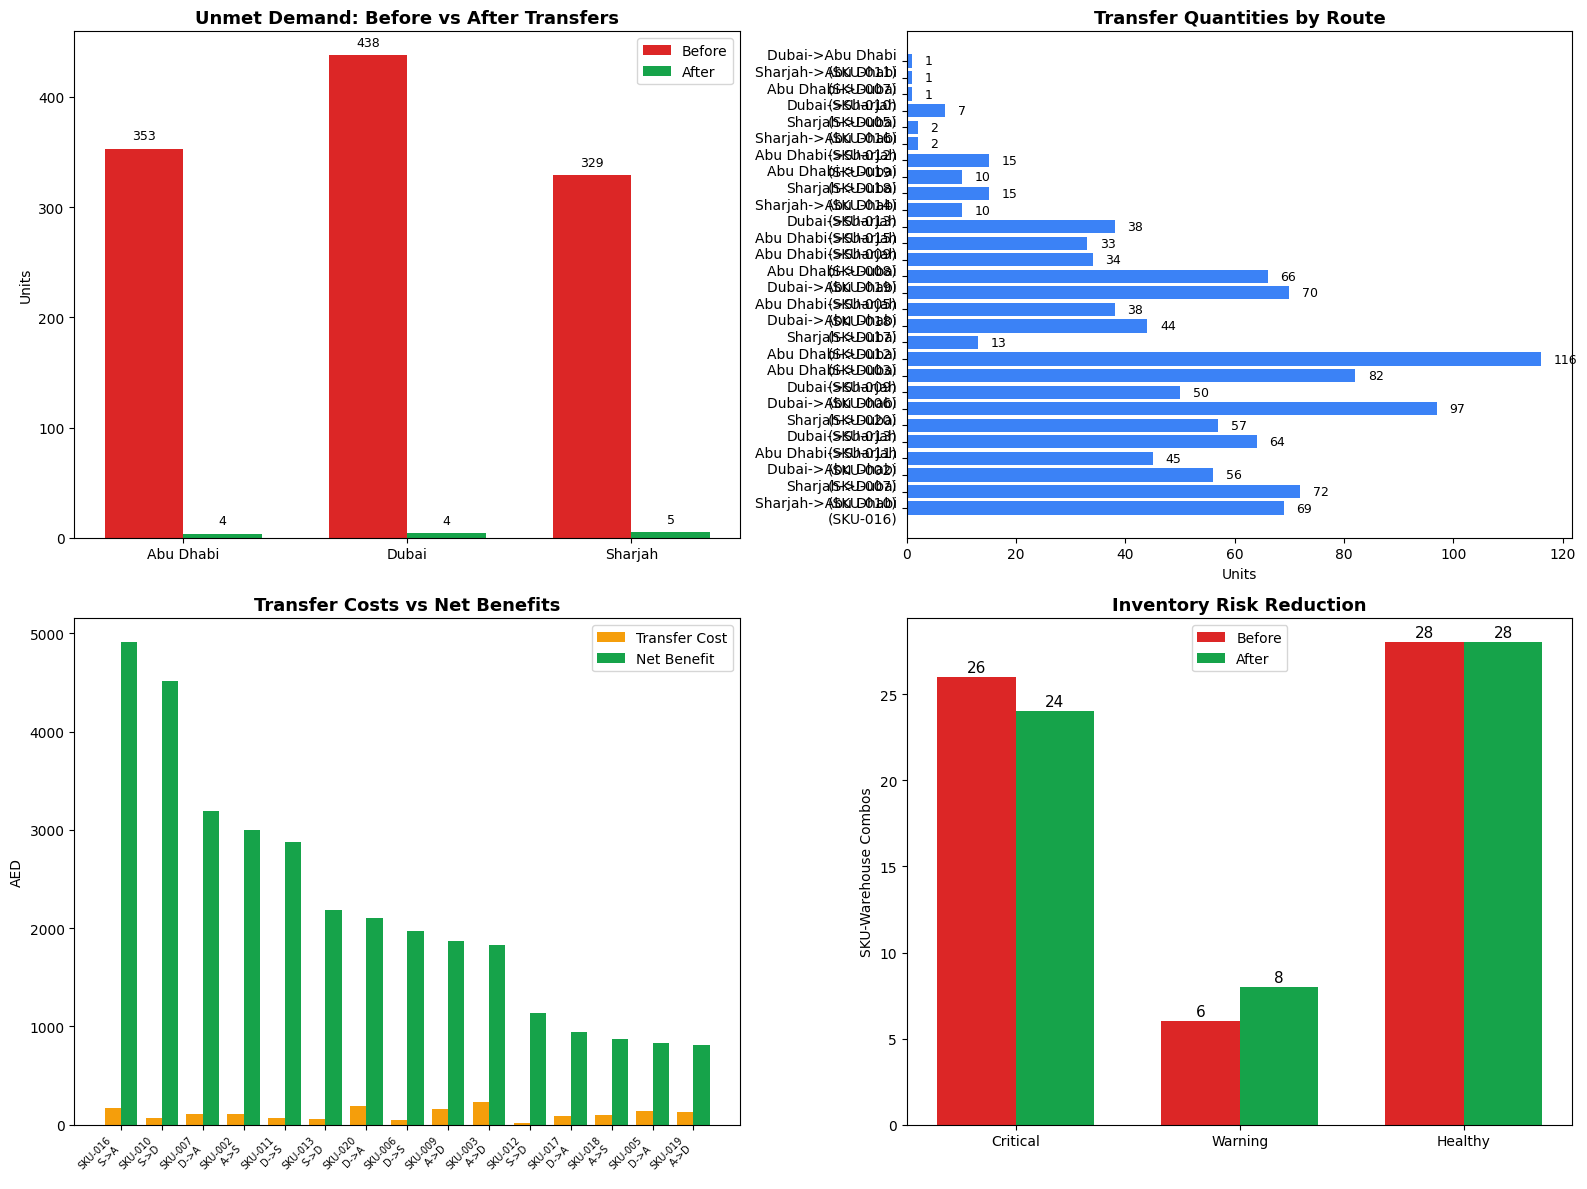

Saved: C:\Users\antho\Desktop\CUD\Semester 7\Hackathon\Problem statement\Datasets\transfer_optimization_charts.png


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Unmet demand before vs after by warehouse
ax = axes[0, 0]
wh_before = []
wh_after = []
for wh in WH_LIST:
    wh_before.append(sum(baseline_summary["combo_results"][(sku, wh)]["Total_Unmet_Demand"] for sku in SKU_LIST))
    wh_after.append(sum(post_summary["combo_results"][(sku, wh)]["Total_Unmet_Demand"] for sku in SKU_LIST))
x_pos = np.arange(len(WH_LIST))
width = 0.35
ax.bar(x_pos - width/2, wh_before, width, label="Before", color="#dc2626")
ax.bar(x_pos + width/2, wh_after, width, label="After", color="#16a34a")
ax.set_xticks(x_pos)
ax.set_xticklabels(WH_LIST)
ax.set_title("Unmet Demand: Before vs After Transfers", fontweight="bold", fontsize=13)
ax.set_ylabel("Units")
ax.legend()
for i in range(len(WH_LIST)):
    ax.text(i - width/2, wh_before[i] + max(wh_before)*0.02, f"{wh_before[i]:.0f}", ha="center", fontsize=9)
    ax.text(i + width/2, wh_after[i] + max(wh_before)*0.02, f"{wh_after[i]:.0f}", ha="center", fontsize=9)

# 2. Transfer quantities between warehouses
ax = axes[0, 1]
if len(recommendations_df) > 0:
    flow_labels = []
    flow_values = []
    for _, r in recommendations_df.iterrows():
        label = f"{r['Source_Warehouse']}->{r['Destination_Warehouse']}\n({r['SKU']})"
        flow_labels.append(label)
        flow_values.append(r["Transfer_Quantity"])
    ax.barh(flow_labels, flow_values, color="#3b82f6")
    ax.set_title("Transfer Quantities by Route", fontweight="bold", fontsize=13)
    ax.set_xlabel("Units")
    for i, v in enumerate(flow_values):
        ax.text(v + max(flow_values)*0.02, i, str(v), va="center", fontsize=9)
else:
    ax.text(0.5, 0.5, "No transfers recommended", ha="center", va="center", fontsize=14)
    ax.set_title("Transfer Quantities by Route", fontweight="bold", fontsize=13)

# 3. Transfer costs and economic benefits
ax = axes[1, 0]
if len(recommendations_df) > 0:
    rec_short = recommendations_df.head(15)
    labels = [f"{r['SKU']}\n{r['Source_Warehouse'][0]}->{r['Destination_Warehouse'][0]}" for _, r in rec_short.iterrows()]
    costs = rec_short["Transfer_Cost_AED"].values
    benefits = rec_short["Estimated_Net_Benefit_AED"].values
    x_pos = np.arange(len(labels))
    ax.bar(x_pos - 0.2, costs, 0.4, label="Transfer Cost", color="#f59e0b")
    ax.bar(x_pos + 0.2, benefits, 0.4, label="Net Benefit", color="#16a34a")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels, fontsize=7, rotation=45, ha="right")
    ax.set_title("Transfer Costs vs Net Benefits", fontweight="bold", fontsize=13)
    ax.set_ylabel("AED")
    ax.legend()
else:
    ax.text(0.5, 0.5, "No transfers", ha="center", va="center", fontsize=14)
    ax.set_title("Transfer Costs vs Net Benefits", fontweight="bold", fontsize=13)

# 4. Inventory risk reduction
ax = axes[1, 1]
risk_before = {"Critical": 0, "Warning": 0, "Healthy": 0}
risk_after = {"Critical": 0, "Warning": 0, "Healthy": 0}
for key in baseline_summary["combo_results"]:
    before = baseline_summary["combo_results"][key]
    after = post_summary["combo_results"][key]
    safety = safety_map[key]
    if before["Total_Unmet_Demand"] > 0:
        risk_before["Critical"] += 1
    elif before["Ending_Stock"] < safety:
        risk_before["Warning"] += 1
    else:
        risk_before["Healthy"] += 1
    if after["Total_Unmet_Demand"] > 0:
        risk_after["Critical"] += 1
    elif after["Ending_Stock"] < safety:
        risk_after["Warning"] += 1
    else:
        risk_after["Healthy"] += 1

categories = ["Critical", "Warning", "Healthy"]
before_vals = [risk_before[c] for c in categories]
after_vals = [risk_after[c] for c in categories]
x_pos = np.arange(len(categories))
ax.bar(x_pos - width/2, before_vals, width, label="Before", color="#dc2626")
ax.bar(x_pos + width/2, after_vals, width, label="After", color="#16a34a")
ax.set_xticks(x_pos)
ax.set_xticklabels(categories)
ax.set_title("Inventory Risk Reduction", fontweight="bold", fontsize=13)
ax.set_ylabel("SKU-Warehouse Combos")
ax.legend()
for i in range(len(categories)):
    ax.text(i - width/2, before_vals[i] + 0.3, str(before_vals[i]), ha="center", fontsize=11)
    ax.text(i + width/2, after_vals[i] + 0.3, str(after_vals[i]), ha="center", fontsize=11)

plt.tight_layout()
plt.savefig(DATA_DIR / "transfer_optimization_charts.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {DATA_DIR / 'transfer_optimization_charts.png'}")

---
## 11. Validation

In [19]:
sep = "=" * 65
print(sep)
print("  VALIDATION CHECKS — Step 4: Stock Transfer Optimization")
print(sep)
print()

checks_passed = 0
checks_total = 0

def check(name, condition, detail=""):
    global checks_passed, checks_total
    checks_total += 1
    status = "PASS" if condition else "FAIL"
    if condition:
        checks_passed += 1
    print(f"  [{status}] {name}: {detail}")
    return condition

# 1. No negative transfer quantities
check("No negative transfer quantities",
      (final_recs_df["Transfer_Quantity"] >= 0).all() if len(final_recs_df) > 0 else True,
      f"{len(final_recs_df)} transfers")

# 2. All transfer quantities are integers
check("All transfer quantities are integers",
      final_recs_df["Transfer_Quantity"].dtype.kind in "iu" if len(final_recs_df) > 0 else True,
      f"dtype={final_recs_df['Transfer_Quantity'].dtype}" if len(final_recs_df) > 0 else "N/A")

# 3. No transfers between the same warehouse
same_wh = (final_recs_df["Source_Warehouse"] == final_recs_df["Destination_Warehouse"]).sum() if len(final_recs_df) > 0 else 0
check("No transfers between same warehouse", same_wh == 0, f"{same_wh} violations")

# 4. All routes exist
routes_exist = 0
routes_missing = 0
for _, r in final_recs_df.iterrows():
    if (r["Source_Warehouse"], r["Destination_Warehouse"]) in route_map:
        routes_exist += 1
    else:
        routes_missing += 1
check("All routes exist", routes_missing == 0, f"{routes_exist} valid, {routes_missing} missing")

# 5. No source inventory allocated twice
alloc_ok = True
alloc_details = []
for (sku, src), grp in final_recs_df.groupby(["SKU", "Source_Warehouse"]):
    total_out = grp["Transfer_Quantity"].sum()
    t_row = transferable_df[(transferable_df["SKU"] == sku) &
                            (transferable_df["Warehouse"] == src)]
    if t_row.empty:
        alloc_ok = False
        alloc_details.append(f"{sku}/{src}: no transferable stock")
    else:
        cap = t_row["Transferable_Stock"].values[0]
        if total_out > cap:
            alloc_ok = False
            alloc_details.append(f"{sku}/{src}: {total_out} > {cap}")
check("No source inventory allocated twice", alloc_ok,
      "; ".join(alloc_details) if alloc_details else "all within capacity")

# 6. Source safety-stock constraints respected
safety_ok = True
safety_details = []
for (sku, src), grp in final_recs_df.groupby(["SKU", "Source_Warehouse"]):
    total_out = grp["Transfer_Quantity"].sum()
    available = available_map[(sku, src)]
    fc30 = forecast_30d_map[(sku, src)]
    safety = safety_map[(sku, src)]
    remaining = available - total_out
    if remaining < safety:
        safety_ok = False
        safety_details.append(f"{sku}/{src}: remaining {remaining:.0f} < safety {safety}")
    # Also check simulation: source should not have unmet demand after transfer
    post_result = post_summary["combo_results"][(sku, src)]
    if post_result["Total_Unmet_Demand"] > 0:
        safety_ok = False
        safety_details.append(f"{sku}/{src}: sim shows unmet {post_result['Total_Unmet_Demand']:.1f}")
check("Source safety-stock respected", safety_ok,
      "; ".join(safety_details) if safety_details else "all sources safe")

# 7. Transfer arrivals respect route lead times
lt_ok = True
lt_count = 0
for _, r in final_recs_df.iterrows():
    route = route_map[(r["Source_Warehouse"], r["Destination_Warehouse"])]
    if r["Lead_Time_Days"] != route["lead_time"]:
        lt_ok = False
    else:
        lt_count += 1
check("Transfer arrivals respect lead times", lt_ok, f"{lt_count} routes verified")

# 8. No negative physical inventory
neg_count = (post_daily["Ending_Stock"] < 0).sum()
check("No negative physical inventory", neg_count == 0, f"{neg_count} negatives in {len(post_daily)} rows")

# 9. Daily inventory balances reconcile
reconcile_ok = True
recon_count = 0
for (sku, wh), grp in post_daily.groupby(["SKU", "Warehouse"]):
    grp = grp.sort_values("Date").reset_index(drop=True)
    for i in range(len(grp) - 1):
        ending = grp.loc[i, "Ending_Stock"]
        starting_next = grp.loc[i + 1, "Starting_Stock"]
        if abs(ending - starting_next) > 0.01:
            reconcile_ok = False
            break
        recon_count += 1
    if not reconcile_ok:
        break
check("Daily balances reconcile", reconcile_ok, f"{recon_count} transitions verified")

# 10. Total transfer quantities balance across sources and destinations
total_out_sum = final_recs_df.groupby(["SKU", "Source_Warehouse"])["Transfer_Quantity"].sum().sum()
total_in_sum = final_recs_df.groupby(["SKU", "Destination_Warehouse"])["Transfer_Quantity"].sum().sum()
check("Transfer quantities balance", total_out_sum == total_in_sum,
      f"out={total_out_sum}, in={total_in_sum}")

# 11. Economic benefits calculated from simulation
sim_unmet_avoided = unmet_before - unmet_after
check("Economic benefits from simulation", sim_unmet_avoided >= 0,
      f"sim avoided={sim_unmet_avoided:.1f} units")

# 12. Post-transfer projection has exactly 1800 rows
check("Post-transfer projection = 1800 rows", len(post_daily) == 1800, f"{len(post_daily)} rows")

# 13. All approval statuses are Pending
check("All approvals Pending",
      (final_recs_df["Approval_Status"] == "Pending").all() if len(final_recs_df) > 0 else True,
      f"{final_recs_df['Approval_Status'].nunique()} unique statuses" if len(final_recs_df) > 0 else "N/A")

print()
print(sep)
if checks_passed == checks_total:
    print(f"  ALL VALIDATION CHECKS PASSED  ({checks_passed}/{checks_total})")
else:
    print(f"  {checks_passed}/{checks_total} CHECKS PASSED, {checks_total - checks_passed} FAILED")
print(sep)

  VALIDATION CHECKS — Step 4: Stock Transfer Optimization

  [PASS] No negative transfer quantities: 28 transfers
  [PASS] All transfer quantities are integers: dtype=int64
  [PASS] No transfers between same warehouse: 0 violations
  [PASS] All routes exist: 28 valid, 0 missing
  [PASS] No source inventory allocated twice: all within capacity
  [PASS] Source safety-stock respected: all sources safe
  [PASS] Transfer arrivals respect lead times: 28 routes verified
  [PASS] No negative physical inventory: 0 negatives in 1800 rows
  [PASS] Daily balances reconcile: 1740 transitions verified
  [PASS] Transfer quantities balance: out=1108, in=1108
  [PASS] Economic benefits from simulation: sim avoided=1107.3 units
  [PASS] Post-transfer projection = 1800 rows: 1800 rows
  [PASS] All approvals Pending: 1 unique statuses

  ALL VALIDATION CHECKS PASSED  (13/13)


---
## 12. Final Report

In [20]:
sep = "=" * 65
print(sep)
print("  STEP 4 REPORT — Stock Transfer Optimization")
print(sep)
print()
print(f"  Recommended transfers       : {len(final_recs_df)}")
print(f"  Total units recommended      : {recommendations_df['Transfer_Quantity'].sum()}")
print(f"  Total transfer cost          : {total_transfer_cost:,.2f} AED")
print(f"  Unmet demand before transfers: {unmet_before:.1f} units")
print(f"  Unmet demand after transfers : {unmet_after:.1f} units")
print(f"  Unmet demand avoided         : {unmet_avoided:.1f} units")
print(f"  Actual margin preserved (sim): {actual_margin_preserved:,.2f} AED")
print(f"  Net economic benefit         : {net_economic_benefit:,.2f} AED")
print(f"  Shortages eliminated         : {eliminated} of {len(shortage_df)}")
print(f"  All approvals Pending        : Yes")
print()
print("  Files Created:")
print(f"    transfer_recommendations.csv              ({len(final_recs_df)} rows)")
print(f"    post_transfer_inventory_projection.csv    ({len(post_daily)} rows)")
print(f"    transfer_optimization_summary.csv         ({len(opt_summary)} rows)")
print(f"    transfer_optimization_charts.png")
print()
print("  Note: All benefits are projected/simulated estimates.")
print("  Transfers require human approval before execution.")
print("  Original files preserved. Step 5 not implemented yet.")
print(sep)

  STEP 4 REPORT — Stock Transfer Optimization

  Recommended transfers       : 28
  Total units recommended      : 1108
  Total transfer cost          : 2,021.50 AED
  Unmet demand before transfers: 1119.7 units
  Unmet demand after transfers : 12.4 units
  Unmet demand avoided         : 1107.3 units
  Actual margin preserved (sim): 46,838.67 AED
  Net economic benefit         : 44,817.17 AED
  Shortages eliminated         : 2 of 26
  All approvals Pending        : Yes

  Files Created:
    transfer_recommendations.csv              (28 rows)
    post_transfer_inventory_projection.csv    (1800 rows)
    transfer_optimization_summary.csv         (20 rows)
    transfer_optimization_charts.png

  Note: All benefits are projected/simulated estimates.
  Transfers require human approval before execution.
  Original files preserved. Step 5 not implemented yet.
